# Linear Combinations of Unitaries

Workspace for testing converting reward-atoms values into non-unitary matrix, then converting that matrix to a linear combination of unitaries (LCU).

In [2027]:
import pennylane as qml
from pennylane import math as qml_math
from pennylane import numpy as np
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.visualization import array_to_latex
from typing import Callable
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from functools import reduce
from scipy.stats import wasserstein_distance

In [2028]:
rng = np.random.default_rng(42)

In [2029]:
dev = qml.device("default.qubit")
# dev = qml.device("default.mixed")
# dev = qml.device("default.qubit", shots=10000)
# dev = qml.device("default.qubit", shots=None)

In [2030]:
def is_unitary(m: np.ndarray):
    return np.allclose(np.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: np.ndarray):
    return np.allclose(m, m.T.conj())

def is_sorted(x: np.ndarray):
    x = np.array(x)
    return bool(np.all(x[:-1] <= x[1:]))

def softmax(x: np.ndarray):
    y = np.exp(x - np.max(x)) # Stabilize to prevent overflow.
    return y / np.sum(y)

In [2031]:
from typing import Any


@qml.qnode(dev)
def circuit(
    wires: list[int],
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)

In [2032]:
def prepare_action_returns(
    wires: list[int], 
    action_probs_vec: np.ndarray, # shape (n_actions,),
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    ):
    # print(f"{action_probs_vec.shape=}")
    # print(f"{returns_probs_matrix.shape=}")
    n_actions = action_probs_vec.shape[0]
    n_returns = returns_probs_matrix.shape[1]
    
    # Get number of qubits needed for actions and returns.
    # (for now) The number of actions and returns must be powers of 2 for this to work properly.
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Partition wires into action and return wires.
    # Wire order is: [action wires, return wires]
    if len(wires) != d_actions + d_returns:
        raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
    wires_action = wires[:d_actions]
    wires_returns = wires[d_actions:]
    # print(f"{wires_action=}, {wires_returns=}")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_action, normalize=False) # Must normalize since inputs are probability vectors.
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=False) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_action)

In [2033]:
n_actions = 4 # 4
n_returns = 8 # 8
d_actions = int(np.log2(n_actions))
d_returns = int(np.log2(n_returns))

In [2034]:
returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

returns_probs_matrix[[0,3]] = returns_probs_matrix[[3,0]] # Swap some rows.

In [2035]:
# returns_atoms_values_original = np.array([1./n_returns]*n_returns) # DOES NOT WORK!
returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/2.) # This works. Monotonically increasing/decreasing probability distribution.
returns_atoms_values = returns_atoms_values_original.copy()

# returns_atoms_values = returns_atoms_values_original.copy() # DOES NOT WORK. Must at least have square-root term.
returns_atoms_values = np.sqrt(returns_atoms_values) # This is minimal working representation. Must at least have square-root of probability distribution. Causes L2-norm of diagonal unitary to be 1.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_actions) # causes a 1:1 match with computing weighted action distribution via expected return.
# returns_atoms_values = np.sqrt(returns_atoms_values*(n_actions*n_returns)/(d_actions*d_returns)*2)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions # causes L2-norm of circuit probs to be close to 1.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_returns/n_actions)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)
# returns_atoms_values = returns_atoms_values + 1j*np.sqrt(1 - returns_atoms_values**2.) # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.sqrt(1 - returns_atoms_values**2.) + 1j*returns_atoms_values # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.exp(2*np.pi*1j*returns_atoms_values)
# returns_atoms_values = returns_atoms_values / np.linalg.norm(returns_atoms_values)
# returns_atoms_values = np.exp(1j*returns_atoms_values)

# # Swap real/imaginary parts.
# r = returns_atoms_values.real.copy()
# i = returns_atoms_values.imag.copy()
# returns_atoms_values.real = i
# returns_atoms_values.imag = r

U_returns_atoms = np.diag(returns_atoms_values)

In [2036]:
action_probs_vec = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec = np.array(action_probs_vec) # Convert to numpy array for vectorization.

In [2037]:
################### LCU - TEST/TEST/TEST
wires = list(range(d_actions + d_returns + d_returns))
wires_actions = wires[:d_actions]
wires_returns = wires[d_actions:-d_returns]
wires_lcu = list(set(wires) - (set(wires_actions).union(set(wires_returns))))
print(f"{d_actions=}")
print(f"{d_returns=}")
print(f"{wires=}")
print(f"{wires_actions=}")
print(f"{wires_returns=}")
print(f"{wires_lcu=}")
########################
# wires = list(range(d_returns + d_returns))
# wires_returns = wires[:d_returns]
# wires_lcu = list(set(wires) - set(wires_returns))
# print(f"{wires=}")
# print(f"{wires_returns=}")
# print(f"{wires_lcu=}")
########################

LCU_coeffs, LCU_ops = qml.pauli_decompose(U_returns_atoms, wire_order=wires_returns).terms()

# # LCU_coeffs = np.abs(LCU_coeffs)
# alphas = (np.sqrt(LCU_coeffs) / np.linalg.norm(np.sqrt(LCU_coeffs)))
# print(f"{LCU_coeffs=}")
# print(f"{alphas=}")
print(f"{LCU_ops=}")

funcs = [
    lambda wires: prepare_action_returns(wires_actions+wires_returns, action_probs_vec, returns_probs_matrix), # Prepare the action and return distributions.
    ####
    # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True), # Apply the return-atom values as an operator even through we know it is not unitary.
    ####
    # lambda wires: reduce(lambda x,y: x@y, [qml.Hadamard(w) for w in wires_actions]),
    ####
    # lambda wires: qml.StatePrep(alphas, wires=wires_lcu),
    # lambda wires: qml.Select(LCU_ops, control=wires_lcu),
    # lambda wires: qml.adjoint(qml.StatePrep(alphas, wires=wires_lcu)),
    ####
    lambda wires: qml.StatePrep(LCU_coeffs, wires=wires_lcu, normalize=True),
    lambda wires: qml.Select(LCU_ops, control=wires_lcu),
    lambda wires: qml.adjoint(qml.StatePrep(LCU_coeffs, wires=wires_lcu, normalize=True)),
    ####
    # lambda wires: qml.PrepSelPrep(qml.pauli_decompose(U_returns_atoms, wire_order=wires_returns), control=wires_lcu),
    ####
    # lambda wires: [qml.measure(wires=w, postselect=0) for w in wires_lcu],
    # lambda wires: qml.PrepSelPrep(qml.pauli_decompose(U_returns_atoms, wire_order=wires_lcu), control=wires_returns),
    ####
    # lambda wires: qml.PrepSelPrep(qml.pauli_decompose(U_returns_atoms, wire_order=wires_lcu), control=wires_returns+wires_actions),
    ###
    # lambda wires: qml.StatePrep(LCU_coeffs, wires=wires_lcu, normalize=True, pad_with=0),
    # lambda wires: qml.Select(LCU_ops, control=wires_lcu+wires_actions),
    # lambda wires: qml.adjoint(qml.StatePrep(LCU_coeffs, wires=wires_lcu, normalize=True, pad_with=0)),
    ####
    # lambda wires: qml.BlockEncode(U_returns_atoms, wires=wires_returns+wires_lcu),
    ####
    # lambda wires: qml.BlockEncode(U_returns_atoms, wires=wires_returns+wires_lcu+wires_actions),
    ####
    # lambda wires: qml.BlockEncode(U_returns_atoms, wires=wires_returns+wires_lcu),
]

# for _ in range(10):
#     funcs.extend([
#         # lambda wires: prepare_action_returns(wires_actions+wires_returns, action_probs_vec, returns_probs_matrix),
#         # lambda wires: qml.BlockEncode(U_returns_atoms, wires=wires_returns+wires_lcu),
#         # lambda wires: qml.PrepSelPrep(qml.pauli_decompose(U_returns_atoms, wire_order=wires_returns), control=wires_lcu),
#         lambda wires: qml.StatePrep(LCU_coeffs, wires=wires_lcu, normalize=True),
#         lambda wires: qml.Select(LCU_ops, control=wires_lcu),
#         lambda wires: qml.adjoint(qml.StatePrep(LCU_coeffs, wires=wires_lcu, normalize=True)),
#     ])

func_measure = lambda wires: (
    qml.state(),
    qml.probs(wires=wires),
    # qml.density_matrix(wires),
    qml.probs(wires=wires_actions),
    qml.probs(wires=wires_returns),
    qml.probs(wires=wires_lcu),
    # qml.probs(wires=wires_returns[:-1]),
    # *[qml.expval(qml.PauliZ(wires=i)) for i in range(d_actions)],
    # *[qml.expval(qml.PauliZ(wires=i)) for i in range(d_returns)],
    # qml.probs(wires=wires_returns, op=qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True))
    # qml.probs(wires=wires_returns, op=qml.DiagonalQubitUnitary(returns_atoms_values, wires=wires_returns))
    # qml.probs(op=qml.Identity(wires=wires_actions)@qml.Hermitian(U_returns_atoms, wires=wires_returns))
    # qml.probs(op=qml.Hermitian(U_returns_atoms, wires=wires_returns))
    ) # Tuple of measurements: state, probs, density matrix, probs actions, probs returns.
(
    state,
    probs,
    # rho,
    probs_actions,
    probs_returns,
    probs_lcu,
    # exp_actions,
    # exp_returns,
    # test_probs_actions,
    ) = circuit(wires, funcs=funcs, func_measure=func_measure)

display(Statevector(state).draw(output='latex', prefix="\\textrm{State:~~}"))
display(array_to_latex(probs, prefix="\\textrm{Probabilities:~~}"))
display(array_to_latex(probs_actions, prefix="\\textrm{Action Probabilities:~~}"))
output_matrix = qml.matrix(circuit, wire_order=wires)(wires, funcs=funcs, func_measure=func_measure)
################### LCU - TEST/TEST/TEST

d_actions=2
d_returns=3
wires=[0, 1, 2, 3, 4, 5, 6, 7]
wires_actions=[0, 1]
wires_returns=[2, 3, 4]
wires_lcu=[5, 6, 7]
LCU_ops=[I(2) @ I(3) @ I(4), I(2) @ I(3) @ Z(4), I(2) @ Z(3) @ I(4), I(2) @ Z(3) @ Z(4), Z(2) @ I(3) @ I(4), Z(2) @ I(3) @ Z(4), Z(2) @ Z(3) @ I(4), Z(2) @ Z(3) @ Z(4)]


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/numpy/tensor.py:155: RuntimeWarning: divide by zero encountered in matmul
  res = super().__array_ufunc__(ufunc, method, *args, **kwargs)
/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/numpy/tensor.py:155: RuntimeWarning: overflow encountered in matmul
  res = super().__array_ufunc__(ufunc, method, *args, **kwargs)
/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/numpy/tensor.py:155: RuntimeWarning: invalid value encountered in matmul
  res = super().__array_ufunc__(ufunc, method, *args, **kwargs)


In [2038]:
qml.BlockEncode(U_returns_atoms, wires=wires_returns+wires_lcu).hyperparameters['norm']

np.float64(0.4008104395612045)

In [2039]:
(U_returns_atoms@np.conj(U_returns_atoms).T).diagonal() # U**2.

tensor([0.01210343, 0.01995518, 0.03290052, 0.05424379, 0.0894329 ,
        0.14744992, 0.24310382, 0.40081044], requires_grad=True)

In [2040]:
np.linalg.norm(U_returns_atoms)

np.float64(1.0)

In [2041]:
output_matrix.shape

(256, 256)

(<Figure size 700x900 with 1 Axes>, <Axes: >)

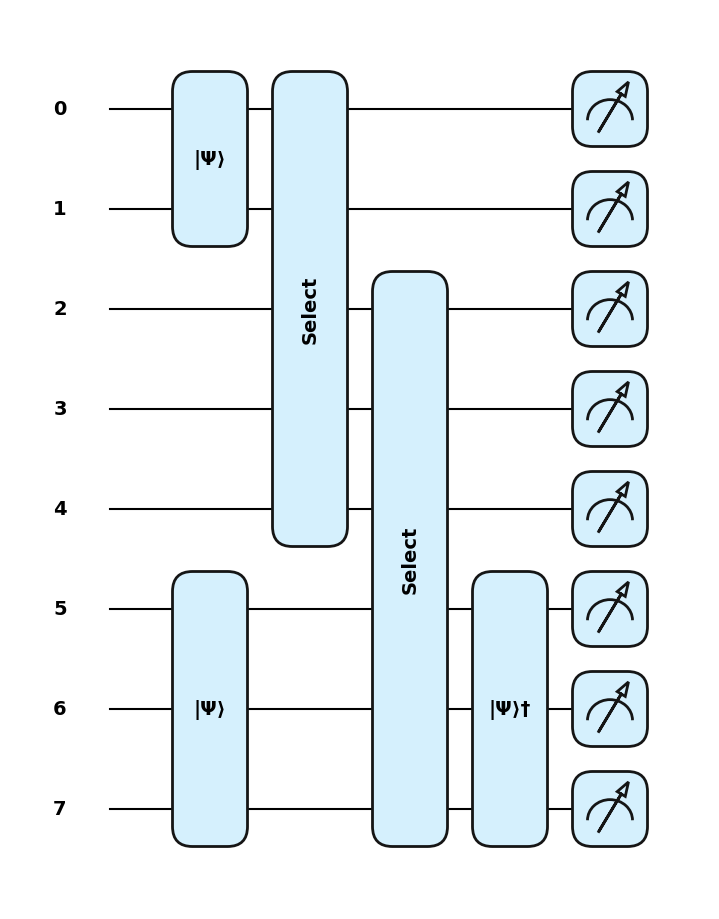

In [2042]:
qml.draw_mpl(circuit, wire_order=wires, style='pennylane')(wires, funcs=funcs, func_measure=func_measure)

In [2043]:
from pennylane.math import partial_trace
output_matrix_reduced = partial_trace(output_matrix, indices=wires_actions)
# output_matrix_reduced = partial_trace(output_matrix, indices=wires_lcu)
output_matrix_reduced.shape, np.real(output_matrix_reduced)

((64, 64),
 tensor([[ 4.23696657e-01, -2.20383281e-18,  5.94850132e-18, ...,
           2.85220154e-18, -1.10631807e-17,  1.16750546e-18],
         [ 3.44942694e-18,  4.23696657e-01,  6.46827798e-19, ...,
           1.75126809e-18, -1.02615469e-18, -8.15237583e-18],
         [-3.22424789e-18,  2.86166486e-19,  4.23696657e-01, ...,
          -1.16750546e-18, -2.37697393e-17,  2.85220154e-18],
         ...,
         [ 9.07980339e-02,  3.59436290e-01, -4.73144292e-02, ...,
           3.63457238e-01, -4.78437270e-02, -1.89395860e-01],
         [ 1.87300563e-01, -4.73144292e-02,  3.59436290e-01, ...,
          -4.78437270e-02,  3.63457238e-01, -9.18137748e-02],
         [-4.73144292e-02, -1.87300563e-01, -9.07980339e-02, ...,
          -1.89395860e-01, -9.18137748e-02, -3.63457238e-01]],
        shape=(64, 64), requires_grad=True))

In [2044]:
# display(array_to_latex(np.real(output_matrix), max_size=2**len(wires)))

In [2045]:
np.real(output_matrix_reduced)[0:U_returns_atoms.shape[0], 0:U_returns_atoms.shape[0]]

tensor([[ 4.23696657e-01, -2.20383281e-18,  5.94850132e-18,
         -2.86166486e-19,  1.23293010e-17, -9.25048100e-19,
          2.76843373e-18, -1.29508730e-19],
        [ 3.44942694e-18,  4.23696657e-01,  6.46827798e-19,
         -6.26871849e-18,  1.18802137e-18, -1.76167110e-17,
          1.66513872e-19, -4.24115961e-18],
        [-3.22424789e-18,  2.86166486e-19,  4.23696657e-01,
         -2.20383281e-18, -8.90266874e-19,  1.29508730e-19,
          1.81509108e-17, -9.25048100e-19],
        [-6.46827798e-19,  9.61502436e-18,  3.44942694e-18,
          4.23696657e-01, -1.66513872e-19,  6.47622720e-18,
          1.18802137e-18, -1.17951012e-17],
        [-1.37131397e-17,  9.16457217e-19, -2.76843373e-18,
          1.64585202e-19,  4.23696657e-01, -2.21220841e-18,
          5.94850132e-18, -2.51969011e-19],
        [-1.14633384e-18,  1.87665705e-17, -3.36723547e-19,
          4.24115961e-18,  3.42277876e-18,  4.23696657e-01,
          7.55631991e-19, -6.26871849e-18],
        [ 8.9026

In [2046]:
# np.real(output_matrix_reduced)[0:U_returns_atoms.shape[0], 0:U_returns_atoms.shape[0]].diagonal() - 

In [2047]:
output_matrix

tensor([[ 1.45332054e-01+0.j, -1.52868070e-18+0.j,  8.35416505e-19+0.j,
         ...,  1.64708215e-18+0.j, -3.46143508e-18+0.j,
          9.47146985e-19+0.j],
        [ 2.42810455e-18+0.j,  1.45332054e-01+0.j,  3.27762739e-19+0.j,
         ..., -8.95387297e-18+0.j, -7.78965356e-19+0.j,
         -6.61085818e-18+0.j],
        [ 5.84338878e-19+0.j,  1.23827155e-19+0.j,  1.45332054e-01+0.j,
         ..., -9.47146985e-19+0.j, -2.28316608e-17+0.j,
          1.64708215e-18+0.j],
        ...,
        [ 1.79248618e-02+0.j,  7.09579881e-02+0.j, -9.34056132e-03+0.j,
         ...,  9.41511618e-02+0.j, -1.23935969e-02+0.j,
         -4.90617284e-02+0.j],
        [ 3.69758745e-02+0.j, -9.34056132e-03+0.j,  7.09579881e-02+0.j,
         ..., -1.23935969e-02+0.j,  9.41511618e-02+0.j,
         -2.37837431e-02+0.j],
        [-9.34056132e-03+0.j, -3.69758745e-02+0.j, -1.79248618e-02+0.j,
         ..., -4.90617284e-02+0.j, -2.37837431e-02+0.j,
         -9.41511618e-02+0.j]], shape=(256, 256), requires_grad=

In [2048]:
np.real(output_matrix)[0:U_returns_atoms.shape[0], 0:U_returns_atoms.shape[0]]

tensor([[ 1.45332054e-01, -1.52868070e-18,  8.35416505e-19,
         -1.23827155e-19,  1.13849378e-17, -1.36804332e-18,
          1.34321374e-18, -2.21925931e-19],
        [ 2.42810455e-18,  1.45332054e-01,  3.27762739e-19,
         -4.46581096e-18,  1.96500047e-18, -7.19717567e-18,
          3.25806767e-19, -2.92498303e-18],
        [ 5.84338878e-19,  1.23827155e-19,  1.45332054e-01,
         -1.52868070e-18, -1.61325114e-18,  2.21925931e-19,
          1.13849378e-17, -1.36804332e-18],
        [-3.27762739e-19,  6.15548385e-18,  2.42810455e-18,
          1.45332054e-01, -3.25806767e-19,  2.87226531e-18,
          1.96500047e-18, -7.19717567e-18],
        [-1.24252776e-17,  1.36463417e-18, -1.34321374e-18,
          2.35845447e-19,  1.45332054e-01, -1.53291496e-18,
          8.35416505e-19, -1.06538702e-19],
        [-1.96703942e-18,  7.75135636e-18, -3.17481779e-19,
          2.92498303e-18,  2.42557212e-18,  1.45332054e-01,
          3.38102622e-19, -4.46581096e-18],
        [ 1.6132

In [2049]:
# lcu = qml.pauli_decompose(U_returns_atoms, wire_order=wires_returns)
# # qml.matrix(lcu)
# display(array_to_latex(qml.matrix(lcu).real / sum(abs(np.array(lcu.terms()[0])))))

In [2050]:
U_returns_atoms.diagonal()

tensor([0.11001557, 0.14126279, 0.18138502, 0.23290297, 0.29905334,
        0.38399208, 0.4930556 , 0.63309592], requires_grad=True)

In [2051]:
returns_atoms_values_original

tensor([0.01210343, 0.01995518, 0.03290052, 0.05424379, 0.0894329 ,
        0.14744992, 0.24310382, 0.40081044], requires_grad=True)

In [2052]:
np.linalg.norm(returns_atoms_values)

np.float64(1.0)

In [2053]:
np.linalg.norm(U_returns_atoms.diagonal())

np.float64(1.0)

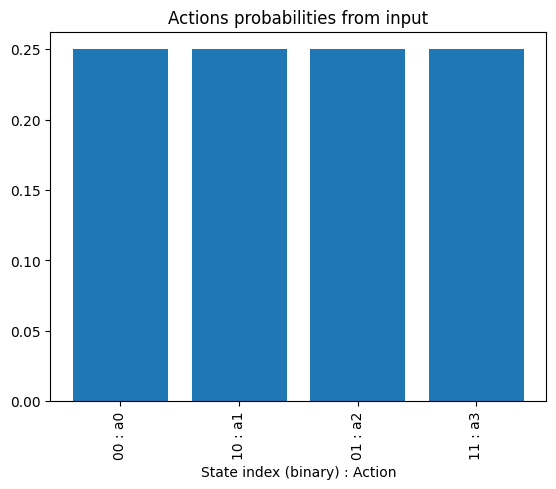

<Figure size 640x480 with 0 Axes>

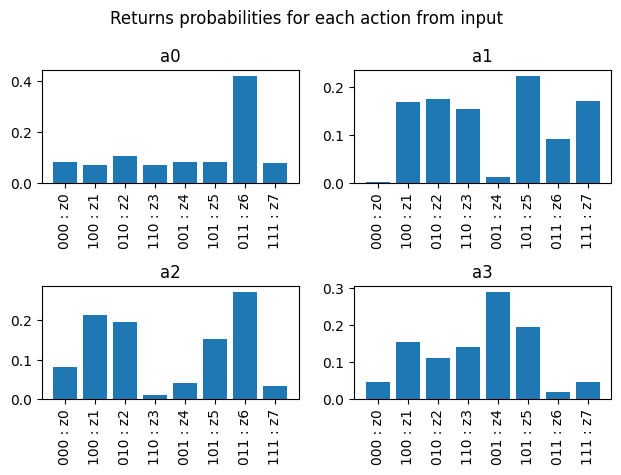

Text(0.5, 0, 'State index (binary) : Return atom')

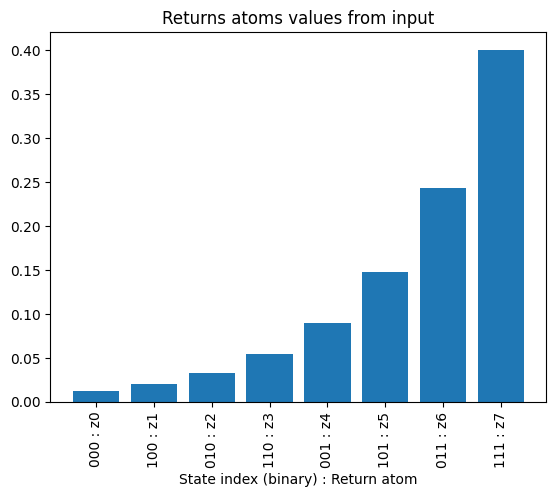

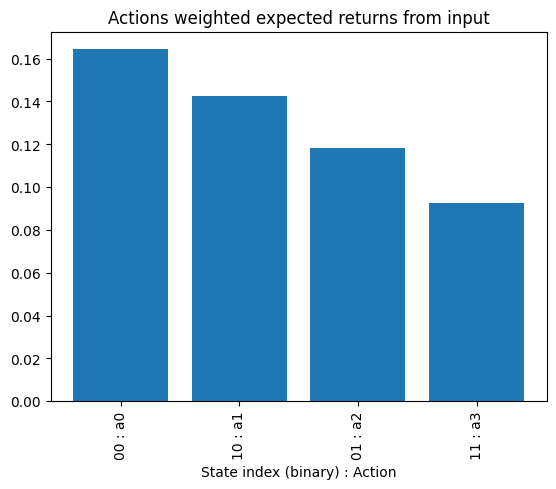

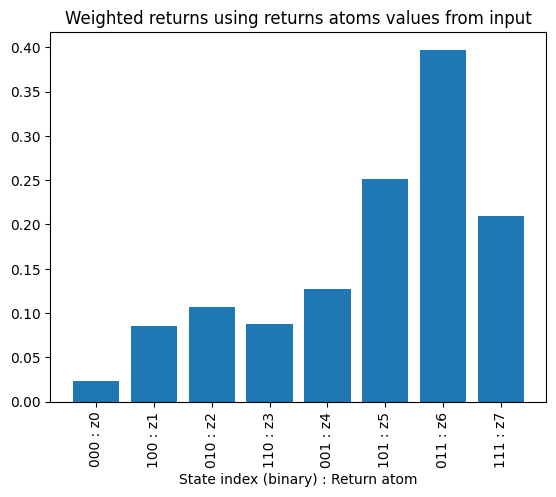

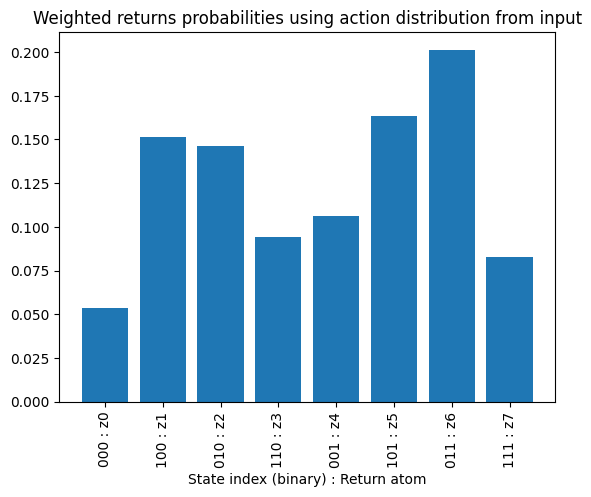

In [2054]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(np.arange(n_actions), action_probs_vec)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions probabilities from input")
plt.xlabel("State index (binary) : Action")


plt.figure()
d = int(np.ceil(np.sqrt(n_actions)))
fig, axs = plt.subplots(d, d)
axs = axs.flatten()
for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), returns_probs_matrix[a])
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}")
plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()


plt.figure()
plt.bar(np.arange(n_returns), returns_atoms_values_original)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Returns atoms values from input")
plt.xlabel("State index (binary) : Return atom")


plt.figure()
plt.bar(np.arange(n_actions), returns_probs_matrix @ returns_atoms_values_original)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions weighted expected returns from input")
plt.xlabel("State index (binary) : Action")

#########

plt.figure()
M = np.einsum('jj,ij->j', U_returns_atoms, returns_probs_matrix)
plt.bar(np.arange(n_returns), np.abs(M))
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Weighted returns using returns atoms values from input")
plt.xlabel("State index (binary) : Return atom")


plt.figure()
df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
weighted_vec = (df.T * weights).sum(axis=1).to_numpy()
plt.bar(np.arange(n_returns), weighted_vec)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Weighted returns probabilities using action distribution from input")
plt.xlabel("State index (binary) : Return atom")

Text(0.5, 0, 'State index (binary) : Return atom')

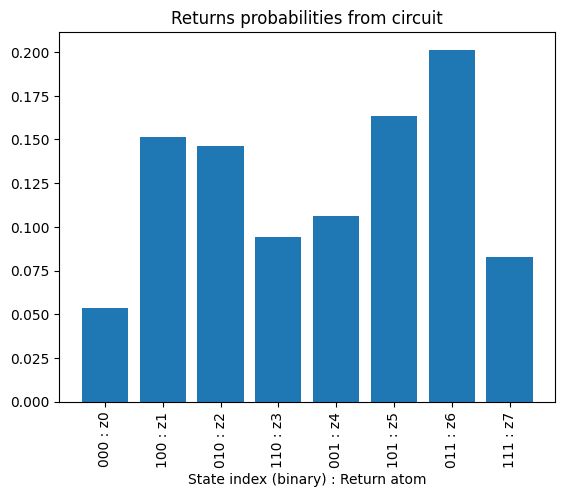

In [2055]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_returns), probs_returns)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Returns probabilities from circuit")
plt.xlabel("State index (binary) : Return atom")

Text(0.5, 0, 'State index (binary) : Ancilla')

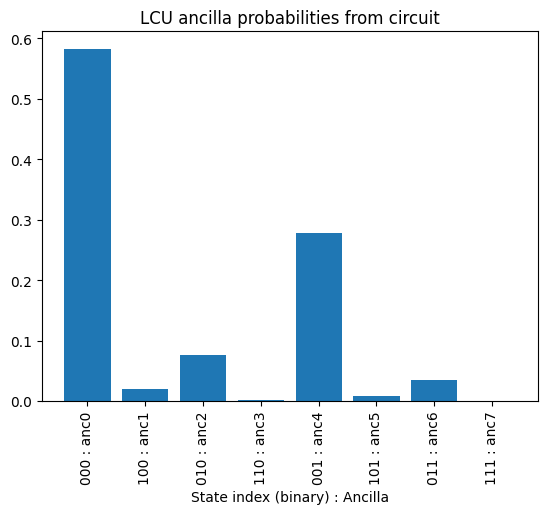

In [2056]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_returns), probs_lcu)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : anc{i}" for i in range(n_returns)], rotation=90)
plt.title("LCU ancilla probabilities from circuit")
plt.xlabel("State index (binary) : Ancilla")

Text(0.5, 0, 'State index (binary) : Action')

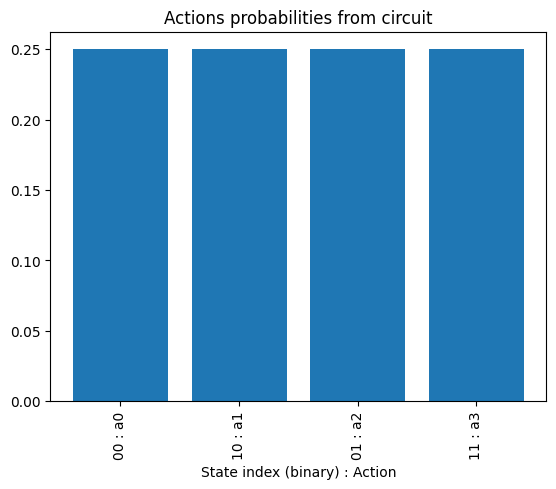

In [2057]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions probabilities from circuit")
plt.xlabel("State index (binary) : Action")

In [2058]:
### Rank actions from high-to-low based on their weighted expected return.

# sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]
action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1])
action_rank_manual_compute

(0, 1, 2, 3)

In [2059]:
### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1])
action_rank_circuit_probs

(0, 3, 2, 1)

In [2060]:
### Verify manually computed action rank is the same as the rank estimated by the circuit.

action_rank_manual_compute == action_rank_circuit_probs

False